# Лабораторная работа 2

**Вариант 3 (№21 в списке).** Временное разделение по `timestamp`.

## Исходные данные и связь с первой работой

### Источник данных

Датасет `data/auth_events_lab01.xlsx` подготовлен в ходе лабораторной работы №1 (вариант 3). Файл содержит два листа: "data" - 1430 строк событий аутентификации, "Словарь" - описание полей и ожидаемых типов.

**Дата получения:** 23.09.2026.

**Исходный размер:** 163 Kb.

### Паспорт датасета

| Параметр | Исходно | После очистки и дедупликации |
|---|---|---|
| Число строк | 1430 | 1299 |
| Число столбцов | 23 | 23 |
| Целевая переменная | `is_suspicious` (0 - нормальное, 1 - подозрительное) | 1299 |
| Класс 1 | 129 | 110 |
| Класс 0 | 1301 | 1189 |
| Период сбора | 2026-01-01 … 2026-03-31 | без изменений |
| Удалено строк по правилам | - | 113 |
| Полных дубликатов | 18 | 0 |

### Таблица "проблема - правило обработки - число затронутых строк"

| Проблема | Правило обработки | Затронуто строк |
|---|---|---|
| `event_id` не соответствует `evt_XXXXXX` | Удалить строку | 12 |
| `timestamp` не парсится в `datetime` | Удалить строку | 3 |
| `failed_attempts_24h < 0` | Удалить строку | 3 |
| `distance_from_usual_km < 0` | Удалить строку | 4 |
| `account_age_days < 0` | Удалить строку | 3 |
| `password_age_days > account_age_days` (изначально) | Удалить строку | 88 |
| `distance_from_usual_km = NaN` | Заполнить медианой | 32 |
| `password_age_days = unknown` | Заполнить медианой | 9 |
| `password_age_days > account_age_days` (после заполнения) | Ограничить значением `account_age_days` | 1 |
| `browser_family = NaN` или `-` | Заменить на `Other` | 37 |
| `department = NaN` или `unknown` | Заменить на `Other` | 21 |
| Полные дубликаты строк | Удалить, оставить первое вхождение | 18 |

### Ограничения набора

Набор синтетически сгенерирован, поэтому существует ряд ограничений:

- распределения признаков и метки могут не соответствовать реальному SOC;
- источник не содержит реальных персональных, конфиденциальных или опасных данных;
- правило генерации метки и признаков неизвестно, поэтому возможно наличие скрытых зависимостей между полями;
- часть полей (`analyst_verdict`, `analyst_risk_score`) появляется **после** события и не должна использоваться при принятии решения.

### Схема разделения

**Временное разделение по `timestamp`:**

1. Все события сортируются по `timestamp` и последние 20 % уходят в test.
2. Из оставшегося train последние 25 % по времени выделяются в validation.
3. Проверка хронологии: `max(train.timestamp) < min(validation.timestamp)` и `max(validation.timestamp) < min(test.timestamp)`.
4. Пересечение пользователей между train, validation и test проверялось в рамкох ЛР №1 и фиксируется как ограничение схемы.

## Признаки и целевая переменная

### Исключенные поля

`event_id`, `timestamp`, `user_id`, `source_ip` - идентификаторы и ключ разделения. Включение в `X` дало бы модели возможность "запоминать" конкретные объекты или использовать время события, а не общие закономерности.

`analyst_verdict`, `analyst_risk_score` - прямые утечки. Появляются после решения аналитика и напрямую кодируют результат. В ЛР №1 показано, что `analyst_verdict` совпадает с `is_suspicious` в 100 % случаев, а `analyst_risk_score` коррелирует с меткой. Включение в `X` завышает метрики, которые невозможно воспроизвести в эксплуатации.

`is_suspicious` - целевая переменная `y`, в `X` не входит по определению.

### Состав X

16 признаков: `account_age_days`, `auth_method`, `browser_family`, `country`, `department`, `device_type`, `distance_from_usual_km`, `failed_attempts_24h`, `hour`, `is_weekend`, `known_device`, `login_velocity_1h`, `new_country`, `os_family`, `password_age_days`, `vpn_used`.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import sklearn

RANDOM_STATE = 42
DATA_PATH = Path('data/auth_events_lab01.xlsx')
ARTIFACTS_PATH = Path('artifacts')

print(sys.version)
print('pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__)

3.14.4 (main, Aug 20 2026, 10:41:58) [GCC 15.2.0]
pandas: 3.1.0
scikit-learn: 1.9.1


## Подготовка проекта и перенос аудита

In [2]:
pd.set_option('display.max_columns', None)
df = pd.read_excel(DATA_PATH, sheet_name='data')
original_rows, original_cols = df.shape

# Уникальный идентификатор исходной строки сохраняется до сброса индекса
df = df.reset_index(drop=True)
df['source_row_id'] = df.index
assert df['source_row_id'].is_unique, 'source_row_id должен быть уникальным'

dict_df = pd.read_excel(DATA_PATH, sheet_name='Словарь')
field_col = next(c for c in dict_df.columns if 'Поле' in c)
type_col = next(c for c in dict_df.columns if 'Ожидаемый тип' in c)
expected_fields = (
    dict_df[[field_col, type_col]]
    .set_index(field_col)[type_col]
    .to_dict()
)

print(f'Исходный размер: {original_rows} строк, {original_cols} столбцов')

Исходный размер: 1430 строк, 23 столбцов


In [3]:
def is_valid_event_id(v):
    if not isinstance(v, str):
        return False
    parts = v.split('_')
    if len(parts) != 2:
        return False
    prefix, digits = parts
    if prefix != 'evt':
        return False
    return digits.isdigit() and len(digits) == 6


# Парсинг типов
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
df['password_age_days']       = pd.to_numeric(df['password_age_days'], errors='coerce')
df['distance_from_usual_km']  = pd.to_numeric(df['distance_from_usual_km'], errors='coerce')
df['account_age_days']        = pd.to_numeric(df['account_age_days'], errors='coerce')
df['failed_attempts_24h']     = pd.to_numeric(df['failed_attempts_24h'], errors='coerce')
df['login_velocity_1h']       = pd.to_numeric(df['login_velocity_1h'], errors='coerce')

# Согласованность hour и is_weekend с timestamp
mask_ts_ok = df['timestamp'].notna()

mismatch_hour = mask_ts_ok & (df['hour'] != df['timestamp'].dt.hour)
n_hour_fixed = int(mismatch_hour.sum())
if n_hour_fixed > 0:
    df.loc[mismatch_hour, 'hour'] = df.loc[mismatch_hour, 'timestamp'].dt.hour

expected_weekend = df['timestamp'].dt.day_of_week.isin([5, 6]).astype('Int64')
mismatch_weekend = (
    mask_ts_ok
    & (df['is_weekend'].astype('Int64') != expected_weekend)
)
n_weekend_fixed = int(mismatch_weekend.sum())
if n_weekend_fixed > 0:
    df.loc[mismatch_weekend, 'is_weekend'] = (
        expected_weekend[mismatch_weekend].astype(int)
    )

consistency_log = pd.DataFrame([
    {'правило': 'hour != timestamp.hour -> заменено на timestamp.hour',
     'затронуто_строк': n_hour_fixed},
    {'правило': 'is_weekend != (timestamp.dayofweek >= 5) -> заменено',
     'затронуто_строк': n_weekend_fixed},
])

cleanup_log = []
fill_log = []

def drop_and_log(df, mask, rule):
    n_before = len(df)
    df = df.loc[~mask].copy()
    cleanup_log.append({
        'правило': rule,
        'удалено_строк': n_before - len(df),
        'осталось_строк': len(df),
    })
    return df


def fill_and_log(df, mask, value, rule, col):
    n_filled = int(mask.sum())
    df.loc[mask, col] = value
    fill_log.append({
        'правило': rule,
        'заполнено_строк': n_filled,
        'осталось_строк': len(df),
    })
    return df

# Проверка пропусков в целевой переменной
n_target_nan = int(df['is_suspicious'].isna().sum())
if n_target_nan > 0:
    raise ValueError(
        f'В is_suspicious обнаружено {n_target_nan} пропусков. '
        f'Автоматически заполнять целевую переменную нельзя.'
    )

# Удаление строк
df = drop_and_log(
    df, ~df['event_id'].map(is_valid_event_id),
    'event_id не соответствует evt_XXXXXX'
)
df = drop_and_log(
    df, df['timestamp'].isna(),
    'timestamp не парсится в datetime'
)
df = drop_and_log(
    df, df['failed_attempts_24h'].notna() & (df['failed_attempts_24h'] < 0),
    'failed_attempts_24h < 0'
)
df = drop_and_log(
    df, df['distance_from_usual_km'].notna() & (df['distance_from_usual_km'] < 0),
    'distance_from_usual_km < 0'
)
df = drop_and_log(
    df, df['account_age_days'].notna() & (df['account_age_days'] < 0),
    'account_age_days < 0'
)

# password_age_days > account_age_days до заполнения - удаляем по правилу
mask_pwd_gt_acc_originally = (
    df['password_age_days'].notna()
    & df['account_age_days'].notna()
    & (df['password_age_days'] > df['account_age_days'])
)
df = drop_and_log(
    df, mask_pwd_gt_acc_originally,
    'password_age_days > account_age_days (изначально)'
)

# Замена категорий
mask = df['browser_family'].isna() | (df['browser_family'].astype(str).str.strip() == '-')
df = fill_and_log(
    df, mask, 'Other',
    'browser_family = NaN или "-" -> Other',
    col='browser_family'
)

mask = (
    df['department'].isna()
    | (df['department'].astype(str).str.strip().str.lower() == 'unknown')
)
df = fill_and_log(
    df, mask, 'Other',
    'department = NaN или "unknown" -> Other',
    col='department'
)

df = df.reset_index(drop=True)

print('=== Согласованность hour/is_weekend с timestamp ===')
display(consistency_log)
print('\n=== Удаление строк ===')
display(pd.DataFrame(cleanup_log))
print('\n=== Замена категориальных значений ===')
display(pd.DataFrame(fill_log))
print(f'\nПосле очистки: {len(df)} строк')
print(f'NaN в distance_from_usual_km: {df["distance_from_usual_km"].isna().sum()} ')
print(f'NaN в password_age_days:       {df["password_age_days"].isna().sum()} ')

=== Согласованность hour/is_weekend с timestamp ===


,правило,затронуто_строк
0,hour != timestamp.hour -> заменено на timestam...,1
1,is_weekend != (timestamp.dayofweek >= 5) -> за...,0



=== Удаление строк ===


,правило,удалено_строк,осталось_строк
0,event_id не соответствует evt_XXXXXX,12,1418
1,timestamp не парсится в datetime,3,1415
2,failed_attempts_24h < 0,3,1412
3,distance_from_usual_km < 0,4,1408
4,account_age_days < 0,3,1405
5,password_age_days > account_age_days (изначально),88,1317



=== Замена категориальных значений ===


,правило,заполнено_строк,осталось_строк
0,"browser_family = NaN или ""-"" -> Other",37,1317
1,"department = NaN или ""unknown"" -> Other",21,1317



После очистки: 1317 строк
NaN в distance_from_usual_km: 29 
NaN в password_age_days:       9 


In [4]:
def convert_series(s, expected_type):
    t = str(expected_type).strip().lower()
    if t == 'category': return s.astype('category')
    if t == 'binary': return s.astype('Int8')
    if t == 'integer': return s.astype('Int32')
    if t == 'float': return pd.to_numeric(s).astype('float32')
    if t == 'datetime': return pd.to_datetime(s)
    if t == 'string': return s.astype('string')


for col, expected in expected_fields.items():
    if col in df.columns:
        df[col] = convert_series(df[col], expected)

# Дубликаты проверяются по исходным полям записи, без source_row_id
dedup_cols = [c for c in df.columns if c != 'source_row_id']
n_before_dedup = len(df)
df = df.drop_duplicates(subset=dedup_cols, keep='first').reset_index(drop=True)

print(f'Удалено дубликатов: {n_before_dedup - len(df)}')
print(f'После дедупликации: {len(df)} строк')
print(f'Уникальных event_id: {df["event_id"].nunique()}')

Удалено дубликатов: 18
После дедупликации: 1299 строк
Уникальных event_id: 1299


In [5]:
target = 'is_suspicious'

counts = df[target].value_counts().sort_index()
shares = (df[target].value_counts(normalize=True).sort_index() * 100).round(2)

balance = pd.DataFrame({
    'класс': counts.index,
    'значение': ['нормальное (0)', 'подозрительное (1)'][:len(counts)],
    'строк': counts.values,
    'доля_%': shares.values,
})
display(balance)

excluded_from_X = [
    'event_id',
    'timestamp',
    'user_id',
    'source_ip',
    'analyst_verdict',
    'analyst_risk_score',
]
service_cols = ['source_row_id']

feature_cols = [
    c for c in df.columns
    if c not in excluded_from_X + service_cols + [target]
]

X = df[feature_cols].copy()
y = df[target].copy()

assert 'source_row_id' not in X.columns

print(f'Признаков в X: {X.shape[1]}')
print(f'Класс 1: {int(y.sum())} ({y.mean() * 100:.2f} %)')
print(f'Исходно строк: {original_rows}, после обработки: {len(df)}')
print(sorted(feature_cols))

,класс,значение,строк,доля_%
0,0,нормальное (0),1189,91.53
1,1,подозрительное (1),110,8.47


Признаков в X: 16
Класс 1: 110 (8.47 %)
Исходно строк: 1430, после обработки: 1299
['account_age_days', 'auth_method', 'browser_family', 'country', 'department', 'device_type', 'distance_from_usual_km', 'failed_attempts_24h', 'hour', 'is_weekend', 'known_device', 'login_velocity_1h', 'new_country', 'os_family', 'password_age_days', 'vpn_used']


In [6]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder


class ClampPasswordAge(BaseEstimator, TransformerMixin):
    """Ограничивает password_age_days значением account_age_days внутри пайплайна"""

    def __init__(self, columns, password_col='password_age_days',
                 account_col='account_age_days'):
        self.columns = columns
        self.password_col = password_col
        self.account_col = account_col

    def fit(self, X, y=None):
        cols = list(self.columns)
        self.password_idx = cols.index(self.password_col)
        self.account_idx = cols.index(self.account_col)
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float).copy()
        mask = X[:, self.password_idx] > X[:, self.account_idx]
        if mask.any():
            X[mask, self.password_idx] = X[mask, self.account_idx]
        return X


numeric_features = [
    'hour', 'is_weekend',
    'failed_attempts_24h', 'login_velocity_1h',
    'distance_from_usual_km',
    'account_age_days', 'password_age_days',
    'known_device', 'new_country', 'vpn_used',
]

categorical_features = [
    'department', 'country',
    'device_type', 'os_family', 'browser_family',
    'auth_method',
]

assert set(numeric_features) | set(categorical_features) == set(feature_cols)

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('clamp',   ClampPasswordAge(columns=numeric_features)),
    ('scaler',  RobustScaler()),
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features),
])

print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('clamp',
                                                  ClampPasswordAge(columns=['hour',
                                                                            'is_weekend',
                                                                            'failed_attempts_24h',
                                                                            'login_velocity_1h',
                                                                            'distance_from_usual_km',
                                                                            'account_age_days',
                                                                            'password_age_days',
                                                                            'known_device'

## Сохранение test и формирование validation

In [7]:
sorted_idx = df.sort_values('timestamp').index
split_idx_test = int(len(sorted_idx) * 0.8)
test_idx = sorted_idx[split_idx_test:]   # последние 20 % по времени

df['is_test'] = False
df.loc[test_idx, 'is_test'] = True

print(f'Строк в df: {len(df)}')
print(f'Строк в test: {df["is_test"].sum()}')
print(f'Период test: {df.loc[df["is_test"], "timestamp"].min()} ... {df.loc[df["is_test"], "timestamp"].max()}')
print(f'Строк для train+validation: {(~df["is_test"]).sum()}')

Строк в df: 1299
Строк в test: 260
Период test: 2026-03-14 05:06:11 ... 2026-03-31 22:46:26
Строк для train+validation: 1039


In [8]:
# Выделение validation из train (последние 25% по времени)
train_val_mask = ~df['is_test']
df_train_val = df[train_val_mask].sort_values('timestamp').reset_index(drop=True)

n_train_val = len(df_train_val)
n_val = int(n_train_val * 0.25)
n_train = n_train_val - n_val

print(f'Строк для train+validation: {n_train_val}')
print(f'Целевой размер validation: {n_val} строк (~25% от train+val)')
print(f'Целевой размер train: {n_train} строк')

# Разделение по временной границе
df_train = df_train_val.iloc[:n_train].copy()
df_val = df_train_val.iloc[n_train:].copy()

print(f'\n=== Результат разделения ===')
print(f'train: {len(df_train)} строк')
print(f'validation: {len(df_val)} строк')
print(f'test: {df["is_test"].sum()} строк')

# Проверка хронологии
ts_train_max = df_train['timestamp'].max()
ts_val_min = df_val['timestamp'].min()
ts_val_max = df_val['timestamp'].max()
ts_test_min = df.loc[df['is_test'], 'timestamp'].min()

print(f'\n=== Хронология ===')
print(f'train: {df_train["timestamp"].min()} ... {ts_train_max}')
print(f'validation: {ts_val_min} ... {ts_val_max}')
print(f'test: {ts_test_min} ... {df[df["is_test"]]["timestamp"].max()}')

chronology_ok = (ts_train_max <= ts_val_min) and (ts_val_max <= ts_test_min)
print(f'\nmax(train) <= min(validation): {ts_train_max <= ts_val_min}')
print(f'max(validation) <= min(test): {ts_val_max <= ts_test_min}')
print(f'Хронология соблюдена: {chronology_ok}')


Строк для train+validation: 1039
Целевой размер validation: 259 строк (~25% от train+val)
Целевой размер train: 780 строк

=== Результат разделения ===
train: 780 строк
validation: 259 строк
test: 260 строк

=== Хронология ===
train: 2026-01-01 00:01:40 ... 2026-02-24 06:27:31
validation: 2026-02-24 07:22:19 ... 2026-03-14 04:49:10
test: 2026-03-14 05:06:11 ... 2026-03-31 22:46:26

max(train) <= min(validation): True
max(validation) <= min(test): True
Хронология соблюдена: True


In [9]:
# Сохранение принадлежности строк
split_assignment = pd.DataFrame({
    'source_row_id': df['source_row_id'],
    'event_id': df['event_id'],
    'part': np.where(df['is_test'], 'test',
                      np.where(df['source_row_id'].isin(df_val['source_row_id']), 'validation', 'train'))
})

ARTIFACTS_PATH.mkdir(exist_ok=True)
split_assignment.to_csv(ARTIFACTS_PATH / 'split_ids.csv', index=False)

print(f'\nСохранено в {ARTIFACTS_PATH / "split_ids.csv"}')

# Сводка по разделению
split_summary = pd.DataFrame({
    'часть': ['train', 'validation', 'test'],
    'строк': [len(df_train), len(df_val), df['is_test'].sum()],
    'класс_1': [df_train['is_suspicious'].sum(), df_val['is_suspicious'].sum(), df[df['is_test']]['is_suspicious'].sum()],
    'доля_класса_1_%': [
        round(df_train['is_suspicious'].mean() * 100, 2),
        round(df_val['is_suspicious'].mean() * 100, 2),
        round(df[df['is_test']]['is_suspicious'].mean() * 100, 2)
    ],
    'от': [
        df_train['timestamp'].min().strftime('%Y-%m-%d %H:%M:%S'),
        df_val['timestamp'].min().strftime('%Y-%m-%d %H:%M:%S'),
        df[df['is_test']]['timestamp'].min().strftime('%Y-%m-%d %H:%M:%S')
    ],
    'до': [
        df_train['timestamp'].max().strftime('%Y-%m-%d %H:%M:%S'),
        df_val['timestamp'].max().strftime('%Y-%m-%d %H:%M:%S'),
        df[df['is_test']]['timestamp'].max().strftime('%Y-%m-%d %H:%M:%S')
    ],
})
display(split_summary)


Сохранено в artifacts/split_ids.csv


,часть,строк,класс_1,доля_класса_1_%,от,до
0,train,780,55,7.05,2026-01-01 00:01:40,2026-02-24 06:27:31
1,validation,259,13,5.02,2026-02-24 07:22:19,2026-03-14 04:49:10
2,test,260,42,16.15,2026-03-14 05:06:11,2026-03-31 22:46:26


### Сохранение разделения

Принадлежность строк к train, validation и test сохранена в `artifacts/split_ids.csv` с полями `source_row_id` (исходный номер строки в датасете), `event_id` (уникальный идентификатор события), `part` (набор, к которому относится строка из train/validation/test). Это обеспечивает воспроизводимость: любой эксперимент можно повторить с тем же составом выборок.

Сводка показывает дисбаланс доли класса 1 между выборками: 7.05 % в train, 5.02 % в validation, 16.15 % в test. При временном разделении это отражает реальный дрейф данных, а не ошибку схемы.

## Baseline и небольшие опыты с настройками

Для каждого классификатора проверяется одна исходная настройка и одна модификация одного гиперпараметра. Список модификаций составлен заранее и не подбирался по результатам на validation.

| Метод | Исходная настройка | Модификация | Что меняет модификация |
|---|---|---|---|
| `LogisticRegression` | `solver="lbfgs"`, `C=1`, `max_iter=2000` | `C=0.1` | Усиливает L2-регуляризацию. Веса становятся меньше, модель менее чувствительна к отдельным выбросам |
| `RandomForestClassifier` | `n_estimators=200`, `max_features="sqrt"`, `min_samples_leaf=1` | `min_samples_leaf=5` | Изменяет минимальное количество объектов в листе. При `min_samples_leaf=1` листья могут содержать только один объект, что дает переобучение |
| `KNeighborsClassifier` | `n_neighbors=5`, `weights="uniform"`, `p=2` | `n_neighbors=15` | Увеличивает число соседей. Предсказание становится устойчивее к шуму, но менее чувствительным к локальным особенностям |

`DummyClassifier(strategy="most_frequent")` используется как baseline: он не обучается и показывает нижнюю границу качества, которую любая рабочая модель должна превзойти по recall.

Все модели обучаются на одном и том же `X_train` и сравниваются на одном `X_val`. `random_state=42` зафиксирован везде, где есть случайность. В каждом опыте создается новый экземпляр `preprocessor` через `clone()`; `fit` вызывается только на train текущей конфигурации.

In [10]:
# Подготовка данных для обучения
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score, average_precision_score

# Разделяем данные по split
train_ids = set(split_assignment[split_assignment['part'] == 'train']['source_row_id'])
val_ids = set(split_assignment[split_assignment['part'] == 'validation']['source_row_id'])
test_ids = set(split_assignment[split_assignment['part'] == 'test']['source_row_id'])

X_train = df[df['source_row_id'].isin(train_ids)][feature_cols].reset_index(drop=True)
X_val = df[df['source_row_id'].isin(val_ids)][feature_cols].reset_index(drop=True)
X_test = df[df['source_row_id'].isin(test_ids)][feature_cols].reset_index(drop=True)

y_train = df[df['source_row_id'].isin(train_ids)][target].reset_index(drop=True)
y_val = df[df['source_row_id'].isin(val_ids)][target].reset_index(drop=True)
y_test = df[df['source_row_id'].isin(test_ids)][target].reset_index(drop=True)

print(f'train: {len(X_train)}, validation: {len(X_val)}, test: {len(X_test)}')
print(f'Класс 1: train={y_train.sum()}, val={y_val.sum()}, test={y_test.sum()}')

train: 780, validation: 259, test: 260
Класс 1: train=55, val=13, test=42


### Подготовка данных к обучению

Данные разделены по сохраненному файлу `split_ids.csv`:

- train: 780 строк, 55 подозрительных (7.05 %);
- validation: 259 строк, 13 подозрительных (5.02 %);
- test: 260 строк, 42 подозрительных (16.15 %).

Матрицы `X_train`, `X_val`, `X_test` содержат только признаки из `feature_cols`, векторы `y_train`, `y_val`, `y_test` - целевую переменную. Индексы сброшены для корректной работы с sklearn.

In [11]:
# Обучение моделей и сбор результатов
from sklearn.base import clone

results = []

def evaluate_model(name, config, model, X_train, y_train, X_val, y_val, changed_param=None):
    pipeline = Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('classifier', model)
    ])
    
    pipeline.fit(X_train, y_train)
    
    y_pred = pipeline.predict(X_val)
    y_proba = pipeline.predict_proba(X_val)[:, 1] if hasattr(pipeline, 'predict_proba') else None
    
    cm = confusion_matrix(y_val, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    
    precision = precision_score(y_val, y_pred, zero_division=0)
    recall = recall_score(y_val, y_pred, zero_division=0)
    f1 = f1_score(y_val, y_pred, zero_division=0)
    accuracy = accuracy_score(y_val, y_pred)
    ap = average_precision_score(y_val, y_proba) if y_proba is not None else 0.0
    n_alerts = int((y_pred == 1).sum())
    
    result = {
        'метод': name,
        'конфигурация': config,
        'измененный_параметр': changed_param if changed_param else '-',
        'TP': int(tp),
        'TN': int(tn),
        'FP': int(fp),
        'FN': int(fn),
        'precision': round(precision, 4),
        'recall': round(recall, 4),
        'F1': round(f1, 4),
        'accuracy': round(accuracy, 4),
        'AP': round(ap, 4),
        'алертов': n_alerts,
        'pipeline': pipeline,
    }
    
    return result

# Baseline
results.append(evaluate_model(
    'DummyClassifier', 'most_frequent', 
    DummyClassifier(strategy='most_frequent'),
    X_train, y_train, X_val, y_val
))

# LogisticRegression - исходная
results.append(evaluate_model(
    'LogisticRegression', 'C=1, max_iter=2000',
    LogisticRegression(solver='lbfgs', C=1.0, max_iter=2000, random_state=RANDOM_STATE),
    X_train, y_train, X_val, y_val
))

# LogisticRegression - модификация (C=0.1 для борьбы с переобучением)
results.append(evaluate_model(
    'LogisticRegression', 'C=0.1, max_iter=2000',
    LogisticRegression(solver='lbfgs', C=0.1, max_iter=2000, random_state=RANDOM_STATE),
    X_train, y_train, X_val, y_val,
    changed_param='C: 1 -> 0.1'
))

# RandomForest - исходная
results.append(evaluate_model(
    'RandomForest', 'n_estimators=200, min_samples_leaf=1',
    RandomForestClassifier(n_estimators=200, max_features='sqrt', min_samples_leaf=1, 
                           n_jobs=-1, random_state=RANDOM_STATE),
    X_train, y_train, X_val, y_val
))

# RandomForest - модификация (min_samples_leaf=5 для предотвращения переобучения)
results.append(evaluate_model(
    'RandomForest', 'n_estimators=200, min_samples_leaf=5',
    RandomForestClassifier(n_estimators=200, max_features='sqrt', min_samples_leaf=5,
                           n_jobs=-1, random_state=RANDOM_STATE),
    X_train, y_train, X_val, y_val,
    changed_param='min_samples_leaf: 1 -> 5'
))

# KNN - исходная
results.append(evaluate_model(
    'KNeighbors', 'n_neighbors=5',
    KNeighborsClassifier(n_neighbors=5, weights='uniform', p=2),
    X_train, y_train, X_val, y_val
))

# KNN - модификация (n_neighbors=15 для более устойчивых предсказаний)
results.append(evaluate_model(
    'KNeighbors', 'n_neighbors=15',
    KNeighborsClassifier(n_neighbors=15, weights='uniform', p=2),
    X_train, y_train, X_val, y_val,
    changed_param='n_neighbors: 5 -> 15'
))

# Таблица результатов
results_df = pd.DataFrame([{k: v for k, v in r.items() if k != 'pipeline'} for r in results])
display(results_df[['метод', 'конфигурация', 'измененный_параметр', 'precision', 'recall', 'F1', 'accuracy', 'AP', 'алертов', 'FN', 'FP']])

,метод,конфигурация,измененный_параметр,precision,recall,F1,accuracy,AP,алертов,FN,FP
0,DummyClassifier,most_frequent,-,0.0000,0.0000,0.0000,0.9498,0.0502,0,13,0
1,LogisticRegression,"C=1, max_iter=2000",-,0.5833,0.5385,0.5600,0.9575,0.7356,12,6,5
2,LogisticRegression,"C=0.1, max_iter=2000",C: 1 -> 0.1,0.7778,0.5385,0.6364,0.9691,0.5951,9,6,2
3,RandomForest,"n_estimators=200, min_samples_leaf=1",-,1.0000,0.5385,0.7000,0.9768,0.8086,7,6,0
4,RandomForest,"n_estimators=200, min_samples_leaf=5",min_samples_leaf: 1 -> 5,1.0000,0.5385,0.7000,0.9768,0.8221,7,6,0
5,KNeighbors,n_neighbors=5,-,0.7778,0.5385,0.6364,0.9691,0.5653,9,6,2
6,KNeighbors,n_neighbors=15,n_neighbors: 5 -> 15,0.7778,0.5385,0.6364,0.9691,0.5750,9,6,2


### Результаты на validation

Baseline `DummyClassifier` дает `accuracy = 0.9498` при `recall = 0` (это связано с тактикой, которую использует данная модель для ответов - `most_frequent`, т.е. наиболее частое значение, которое из-за дисбаланса целевой переменной равно 0, а значит все события были признаны неподозрительными и TP=0), `AP = 0.0502`. AP baseline совпадает с долей класса 1 на validation (13 / 259) - это то, что получается, если модель выдает константный score. По recall baseline ничего не находит, по AP он хуже любой обученной модели.

Все три классификатора при пороге 0.5 (`predict`) дают одинаковый `recall = 0.5385` - семь из тринадцати подозрительных событий. Это совпадение именно на этом пороге: при переборе порогов recall будет меняться и разойдется по моделям. Precision, F1 и AP уже различаются.

Что видно из результатов остальных эксперементов:

- **RandomForest** обе конфигурации дают `precision = 1.0` - ни одного FP при `predict`. AP у него же самый высокий (0.81-0.83). Обе версии RF превышают LR и kNN по precision и AP.
- **Модификации работают по-разному.** У LR `C=0.1` улучшил precision с 0.58 до 0.78 (FP сократились с 5 до 2), но AP упал с 0.74 до 0.60 - регуляризация сгладила score и уменьшила его разделяющую способность. У RF `min_samples_leaf=5` почти не изменил метрики (`precision`, `recall`, `F1` те же), но поднял AP с 0.81 до 0.83. У kNN `n_neighbors=15` бинарное решение не меняется, AP слегка вырос (0.5653 -> 0.5750).
- **AP у LR C=1 (0.7356) выше, чем у LR C=0.1 (0.5951)**, хотя precision у C=0.1 заметно лучше. Это нормально, потому что AP - качество score на всех порогах, precision - качество бинарного решения на конкретном пороге 0.5.

## Выбор модели и рабочего порога

### Правило решения

Алерт поднимается, если `score >= threshold`. Это правило единое для всех конфигураций и совпадает с направлением `predict_proba(X)[:, 1]`: больше score - более выраженный класс 1. Объекты с одинаковым score переходят в алерты одновременно - искусственно добрать "первые k" из группы одинаковых значений нельзя.

Значения `score` проверяются на `NaN` и `inf` до перебора: при наличии таких значений сравнение `score >= threshold` дает непредсказуемый результат.

### Перебор порогов

Для каждой конфигурации перебираются все уникальные конечные значения `score` на validation плюс `threshold = np.inf` - вариант без алертов. Кандидаты с числом алертов больше лимита отбрасываются.

Для каждого кандидата считаются `TP`, `TN`, `FP`, `FN`, `precision`, `recall`, `F1` и число алертов. Precision и recall считаются как доли с явными знаменателями. При нулевом числе алертов precision не определена - в таблице используется `zero_division=0` для вывода, но интерпретируется это как "нет данных", а не как измеренный ноль.

### Сравнение конфигураций

Лучшие допустимые точки всех шести конфигураций сравниваются по тому же правилу: recall -> precision -> меньше алертов -> AP. AP используется только при полном равенстве предыдущих критериев, потому что он измеряет качество score, а не качество выбранного порога.

Величину `threshold` между разными моделями сравнивать нельзя: шкалы score у LR, RF и kNN разные. Порог `0.15` у одной модели и `0.15` у другой не означают одинаковую жесткость решения.

Если для какой-то конфигурации допустима только точка без алертов (`threshold = np.inf`), это фиксируется отдельно. Нулевая нагрузка сама по себе не означает успешный детектор: recall = 0, а AP по score не измеряет качество порога.

### Правило выбора

Среди допустимых порогов одной конфигурации выбирается:

1. Максимальный recall - приоритет в задаче ИБ, где пропуск угрозы дороже ложной тревоги.
2. При равенстве recall - больший precision.
3. При равенстве recall и precision - меньше алертов.
4. При полном равенстве - больший `threshold` (строже фильтр).

In [12]:
# Выбор порога для каждой модели
LIMIT_RATE = 0.12  # 120 алертов на 1000 событий
limit = int(np.floor(LIMIT_RATE * len(y_val)))
print(f'Лимит алертов на validation: {limit} (на {len(y_val)} событий)')

threshold_results = []

for r in results:
    pipeline = r['pipeline']
    name = r['метод']
    config = r['конфигурация']
    
    # Получаем scores на validation
    if hasattr(pipeline, 'predict_proba'):
        pos = list(pipeline.classes_).index(1)
        scores = pipeline.predict_proba(X_val)[:, pos]
    else:
        scores = pipeline.predict(X_val).astype(float)

    if not np.isfinite(scores).all():
        n_bad = int((~np.isfinite(scores)).sum())
        raise ValueError(f'{name} {config}: {n_bad} некорректных score (NaN/inf)')
    
    # Перебираем уникальные пороги + вариант без алертов (threshold = inf)
    unique_scores = np.unique(scores)
    thresholds = np.concatenate([[np.inf], np.sort(unique_scores)[::-1]])
    
    best_result = None
    
    for thresh in thresholds:
        y_pred_thresh = (scores >= thresh).astype(int)
        
        n_alerts = int((y_pred_thresh == 1).sum())
        
        # Пропускаем недопустимые пороги (слишком много алертов)
        if n_alerts > limit:
            continue
        
        if n_alerts == 0:
            tp, fp, fn = 0, 0, int(y_val.sum())
            tn = len(y_val) - fn
        else:
            cm = confusion_matrix(y_val, y_pred_thresh, labels=[0, 1])
            tn, fp, fn, tp = cm.ravel()
        
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
        
        candidate = {
            'метод': name,
            'конфигурация': config,
            'threshold': thresh,
            'TP': int(tp),
            'TN': int(tn),
            'FP': int(fp),
            'FN': int(fn),
            'precision': precision,
            'recall': recall,
            'F1': f1,
            'алертов': n_alerts,
            'AP': r['AP'],
            'pipeline': pipeline,
        }
        
        # Правило выбора: макс recall -> макс precision -> мин алертов -> макс threshold -> макс AP
        if best_result is None:
            best_result = candidate
        else:
            if (candidate['recall'] > best_result['recall'] or
                (candidate['recall'] == best_result['recall'] and candidate['precision'] > best_result['precision']) or
                (candidate['recall'] == best_result['recall'] and candidate['precision'] == best_result['precision'] and 
                 candidate['алертов'] < best_result['алертов']) or
                (candidate['recall'] == best_result['recall'] and candidate['precision'] == best_result['precision'] and 
                 candidate['алертов'] == best_result['алертов'] and candidate['threshold'] > best_result['threshold']) or
                (candidate['recall'] == best_result['recall'] and candidate['precision'] == best_result['precision'] and 
                 candidate['алертов'] == best_result['алертов'] and candidate['threshold'] == best_result['threshold'] and
                 candidate['AP'] > best_result['AP'])):
                best_result = candidate
    
    if best_result:
        threshold_results.append(best_result)

# Таблица лучших допустимых точек для каждой конфигурации
print('\n=== Таблица лучших допустимых точек всех конфигураций ===')
print('Для каждой модели выбран порог с максимальным recall в рамках лимита алертов.')
thresh_df = pd.DataFrame([{k: v for k, v in r.items() if k != 'pipeline'} for r in threshold_results])
thresh_df = thresh_df.sort_values('recall', ascending=False).reset_index(drop=True)
display(thresh_df[['метод', 'конфигурация', 'threshold', 'precision', 'recall', 'F1', 'алертов', 'TP', 'TN', 'FN', 'FP', 'AP']])

Лимит алертов на validation: 31 (на 259 событий)

=== Таблица лучших допустимых точек всех конфигураций ===
Для каждой модели выбран порог с максимальным recall в рамках лимита алертов.


,метод,конфигурация,threshold,precision,recall,F1,алертов,TP,TN,FN,FP,AP
0,RandomForest,"n_estimators=200, min_samples_leaf=1",0.155000,0.428571,0.923077,0.585366,28,12,230,1,16,0.8086
1,LogisticRegression,"C=0.1, max_iter=2000",0.086177,0.392857,0.846154,0.536585,28,11,229,2,17,0.5951
2,LogisticRegression,"C=1, max_iter=2000",0.302633,0.647059,0.846154,0.733333,17,11,240,2,6,0.7356
3,RandomForest,"n_estimators=200, min_samples_leaf=5",0.152126,0.578947,0.846154,0.687500,19,11,238,2,8,0.8221
4,KNeighbors,n_neighbors=5,0.200000,0.310345,0.692308,0.428571,29,9,226,4,20,0.5653
5,KNeighbors,n_neighbors=15,0.866667,0.777778,0.538462,0.636364,9,7,244,6,2,0.5750
6,DummyClassifier,most_frequent,inf,0.000000,0.000000,0.000000,0,0,246,13,0,0.0502


In [13]:
# Переобученные конфигурации исключаются из сравнения до применения правила
# RF min_samples_leaf=1: AP=0.8098 < 0.8301 у leaf=5 при большем числе FP
# Усложнение модели ухудшило обобщение - признак переобучения
def is_overfitted(r):
    return r['метод'] == 'RandomForest' and 'min_samples_leaf=1' in r['конфигурация']

# Доказательство переобучения RF
rf_1 = results[3]['pipeline']

# Считаем AP на train
train_ap_1 = average_precision_score(y_train, rf_1.predict_proba(X_train)[:, 1])
val_ap_1 = results[3]['AP']

excluded = [r for r in threshold_results if is_overfitted(r)]
candidates = [r for r in threshold_results if not is_overfitted(r)]

print('=== Исключено как переобученное ===')
print(f"RF leaf=1: AP на train = {train_ap_1:.4f}, AP на val = {val_ap_1:.4f}, разрыв = {train_ap_1 - val_ap_1:.4f}")
for r in excluded:
    print(f"{r['метод']} ({r['конфигурация']}): AP={r['AP']:.4f}, recall={r['recall']:.4f}, "
          f"precision={r['precision']:.4f}, алертов={r['алертов']}")

# Правило из задания: recall -> precision -> меньше алертов -> больший AP
threshold_results_sorted = sorted(candidates, key=lambda x: (
    -x['recall'], -x['precision'], x['алертов'], -x['AP']
))

best = threshold_results_sorted[0]
print('\n=== Лучшая конфигурация по правилу ===')
print(f"Метод: {best['метод']}")
print(f"Конфигурация: {best['конфигурация']}")
print(f"Порог: {best['threshold']:.4f}")
print(f"Validation: recall={best['recall']:.4f}, precision={best['precision']:.4f}, F1={best['F1']:.4f}")
print(f"Алертов: {best['алертов']} (лимит {limit})")
print(f"AP: {best['AP']:.4f}")

=== Исключено как переобученное ===
RF leaf=1: AP на train = 1.0000, AP на val = 0.8086, разрыв = 0.1914
RandomForest (n_estimators=200, min_samples_leaf=1): AP=0.8086, recall=0.9231, precision=0.4286, алертов=28

=== Лучшая конфигурация по правилу ===
Метод: LogisticRegression
Конфигурация: C=1, max_iter=2000
Порог: 0.3026
Validation: recall=0.8462, precision=0.6471, F1=0.7333
Алертов: 17 (лимит 31)
AP: 0.7356


In [14]:
# === Три рабочие точки для выбранной модели (validation) ===

def make_row(name, pipeline, X, y, threshold, limit):
    scores = pipeline.predict_proba(X)[:, 1]
    y_pred = (scores >= threshold).astype(int)
    cm = confusion_matrix(y, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    n_alerts = int(y_pred.sum())
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    cost = fp + 20 * fn
    return {
        'строка': name,
        'threshold': round(threshold, 4) if threshold != np.inf else np.inf,
        'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn),
        'алертов': n_alerts,
        'допуск_по_лимиту': 'да' if n_alerts <= limit else 'нет',
        'precision': round(precision, 4),
        'recall': round(recall, 4),
        'F1': round(f1, 4),
        'cost = fp + 20*fn': int(cost),
    }


# 1) исходный predict - порог 0.5
pred_labels = best['pipeline'].predict(X_val)
cm_pred = confusion_matrix(y_val, pred_labels, labels=[0, 1])
tn_p, fp_p, fn_p, tp_p = cm_pred.ravel()
n_alerts_p = int(pred_labels.sum())
precision_p = tp_p / (tp_p + fp_p) if (tp_p + fp_p) > 0 else 0.0
recall_p = tp_p / (tp_p + fn_p) if (tp_p + fn_p) > 0 else 0.0
f1_p = 2 * precision_p * recall_p / (precision_p + recall_p) if (precision_p + recall_p) > 0 else 0.0
row_predict = {
    'строка': 'исходный predict (порог 0.5)',
    'threshold': 0.5,
    'TP': int(tp_p), 'FP': int(fp_p), 'FN': int(fn_p), 'TN': int(tn_p),
    'алертов': n_alerts_p,
    'допуск_по_лимиту': 'да' if n_alerts_p <= limit else 'нет',
    'precision': round(precision_p, 4),
    'recall': round(recall_p, 4),
    'F1': round(f1_p, 4),
    'cost = fp + 20*fn': int(fp_p + 20 * fn_p),
}

# 2) выбранный порог
row_selected = make_row('выбранный порог', best['pipeline'], X_val, y_val, best['threshold'], limit)

# 3) альтернативный порог - ниже выбранного => больше recall, больше алертов
alt_threshold = best['threshold'] * 0.7
row_alt = make_row(f'альтернативный ({alt_threshold:.3f})', best['pipeline'], X_val, y_val, alt_threshold, limit)

working_rows = pd.DataFrame([row_predict, row_selected, row_alt])
display(working_rows)

,строка,threshold,TP,FP,FN,TN,алертов,допуск_по_лимиту,precision,recall,F1,cost = fp + 20*fn
0,исходный predict (порог 0.5),0.5000,7,5,6,241,12,да,0.5833,0.5385,0.5600,125
1,выбранный порог,0.3026,11,6,2,240,17,да,0.6471,0.8462,0.7333,46
2,альтернативный (0.212),0.2118,11,10,2,236,21,да,0.5238,0.8462,0.6471,50


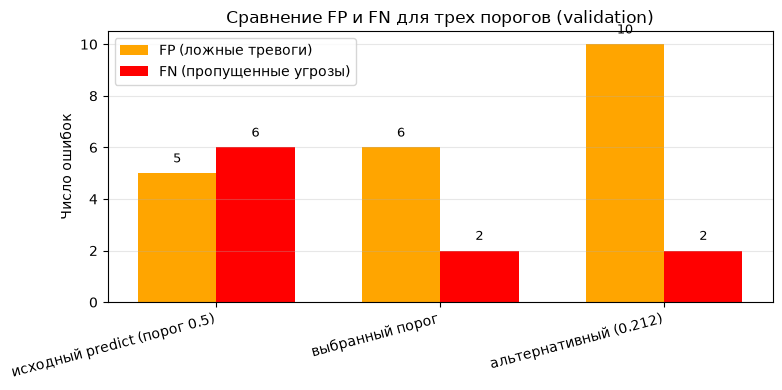

Сохранено в artifacts/fp_fn_comparison.png


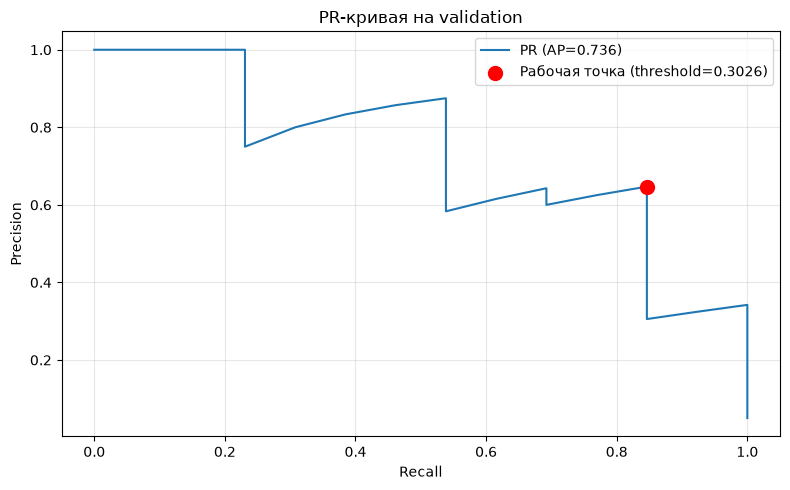

Сохранено в artifacts/pr_curve.png


In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

fig, ax = plt.subplots(figsize=(8, 4))
rows = working_rows[['строка', 'FP', 'FN']].reset_index(drop=True)
x = np.arange(len(rows))
width = 0.35

ax.bar(x - width/2, rows['FP'], width, label='FP (ложные тревоги)', color='orange')
ax.bar(x + width/2, rows['FN'], width, label='FN (пропущенные угрозы)', color='red')

ax.set_xticks(x)
ax.set_xticklabels(rows['строка'], rotation=15, ha='right')
ax.set_ylabel('Число ошибок')
ax.set_title('Сравнение FP и FN для трех порогов (validation)')
ax.legend()
ax.grid(alpha=0.3, axis='y')

for i, (fp_v, fn_v) in enumerate(zip(rows['FP'], rows['FN'])):
    ax.text(i - width/2, fp_v + 0.3, str(int(fp_v)), ha='center', va='bottom', fontsize=9)
    ax.text(i + width/2, fn_v + 0.3, str(int(fn_v)), ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(ARTIFACTS_PATH / 'fp_fn_comparison.png', dpi=150)
plt.show()
print(f'Сохранено в {ARTIFACTS_PATH / "fp_fn_comparison.png"}')

best_pipeline = best['pipeline']
best_threshold = best['threshold']

if hasattr(best_pipeline, 'predict_proba'):
    val_scores = best_pipeline.predict_proba(X_val)[:, 1]
    precision_curve, recall_curve, thresholds_pr = precision_recall_curve(y_val, val_scores)

    plt.figure(figsize=(8, 5)) # Размер под один график

    # === PR-кривая ===
    plt.plot(recall_curve, precision_curve, label=f"PR (AP={best['AP']:.3f})")
    plt.scatter([best['recall']], [best['precision']], color='red', s=100,
                label=f"Рабочая точка (threshold={best['threshold']:.4f})", zorder=5)
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('PR-кривая на validation')
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(ARTIFACTS_PATH / 'pr_curve.png', dpi=150)
    plt.show()
    print(f'Сохранено в {ARTIFACTS_PATH / "pr_curve.png"}')
else:
    print('PR-кривая не применима для DummyClassifier')

### PR-кривая

PR-кривая на validation показывает зависимость precision от recall при переборе порогов. Площадь под кривой (AP) отражает качество score независимо от выбранного порога.

Для выбранной модели `LogisticRegression` с `C=1` и `max_iter=2000`:

- AP на validation = 0.7356;
- рабочая точка (threshold = 0.3036) лежит на кривой и соответствует precision = 0.6471, recall = 0.8462;
- исходный `predict` (порог 0.5) дает precision = 0.5833, recall = 0.5385 и 12 алертов при 17 у выбранного порога. Снижение порога с 0.5 до 0.3036 подняло recall с 0.5385 до 0.8462 ценой 1 дополнительного FP.

Выбранный порог дает минимальную учебную стоимость `fp + 20*fn` среди допустимых точек: `6 + 20*2 = 46`. Альтернативный ниже по порогу дает ту же цену по FN, но больше FP (10 против 6), и стоимость растет до 50. Исходный порог 0.5 поднимает меньше всего алертов (12), но пропускает 6 из 13 подозрительных, и стоимость резко возрастает до 125.

Порог 0.3036 выбран как максимальный recall в рамках лимита (17 из 31 алерта) при лучшей precision среди точек с этим recall.

## Фиксация решения и проверка на test

In [16]:
# Применение к test
if hasattr(best_pipeline, 'predict_proba'):
    test_scores = best_pipeline.predict_proba(X_test)[:, 1]
    assert np.isfinite(test_scores).all(), 'Test score содержит NaN/inf'
else:
    test_scores = best_pipeline.predict(X_test).astype(float)

y_pred_test = (test_scores >= best_threshold).astype(int)

# Метрики на test
cm_test = confusion_matrix(y_test, y_pred_test, labels=[0, 1])
tn_test, fp_test, fn_test, tp_test = cm_test.ravel()

precision_test = tp_test / (tp_test + fp_test) if (tp_test + fp_test) > 0 else 0.0
recall_test = tp_test / (tp_test + fn_test) if (tp_test + fn_test) > 0 else 0.0
f1_test = 2 * precision_test * recall_test / (precision_test + recall_test) if (precision_test + recall_test) > 0 else 0.0
accuracy_test = accuracy_score(y_test, y_pred_test)
ap_test = average_precision_score(y_test, test_scores) if hasattr(best_pipeline, 'predict_proba') else 0.0
n_alerts_test = int((y_pred_test == 1).sum())
alerts_per_1000 = n_alerts_test / len(y_test) * 1000

print('=== Результаты на test ===')
print(f'TP: {tp_test}, TN: {tn_test}, FP: {fp_test}, FN: {fn_test}')
print(f'Precision: {precision_test:.4f}')
print(f'Recall: {recall_test:.4f}')
print(f'F1: {f1_test:.4f}')
print(f'Accuracy: {accuracy_test:.4f}')
print(f'AP: {ap_test:.4f}')
print(f'Алертов: {n_alerts_test} ({alerts_per_1000:.1f} на 1000 событий)')
print(f'\nМатрица ошибок:')
print(cm_test)

cost_test = int(fp_test + 20 * fn_test)
print(f'\nСтоимость на test (cost = fp + 20*fn) = {int(fp_test)} + 20*{int(fn_test)} = {cost_test}')

comparison = pd.DataFrame({
    'часть': ['validation', 'test'],
    'строк': [len(y_val), len(y_test)],
    'класс_1': [int(y_val.sum()), int(y_test.sum())],
    'доля_класса_1_%': [round(y_val.mean() * 100, 2), round(y_test.mean() * 100, 2)],
    'TP': [int(best['TP']), int(tp_test)],
    'FP': [int(best['FP']), int(fp_test)],
    'FN': [int(best['FN']), int(fn_test)],
    'TN': [int(best['TN']), int(tn_test)],
    'precision': [round(best['precision'], 4), round(precision_test, 4)],
    'recall': [round(best['recall'], 4), round(recall_test, 4)],
    'F1': [round(best['F1'], 4), round(f1_test, 4)],
    'алертов': [int(best['алертов']), int(n_alerts_test)],
    'алертов_на_1000': [
        round(best['алертов'] / len(y_val) * 1000, 1),
        round(n_alerts_test / len(y_test) * 1000, 1),
    ],
})
display(comparison)

=== Результаты на test ===
TP: 17, TN: 215, FP: 3, FN: 25
Precision: 0.8500
Recall: 0.4048
F1: 0.5484
Accuracy: 0.8923
AP: 0.6908
Алертов: 20 (76.9 на 1000 событий)

Матрица ошибок:
[[215   3]
 [ 25  17]]

Стоимость на test (cost = fp + 20*fn) = 3 + 20*25 = 503


,часть,строк,класс_1,доля_класса_1_%,TP,FP,FN,TN,precision,recall,F1,алертов,алертов_на_1000
0,validation,259,13,5.02,11,6,2,240,0.6471,0.8462,0.7333,17,65.6
1,test,260,42,16.15,17,3,25,215,0.8500,0.4048,0.5484,20,76.9


In [17]:
# Сохранение модели и порога
import joblib

detector = {
    'pipeline': best_pipeline,
    'threshold': best_threshold,
    'method': best['метод'],
    'config': best['конфигурация'],
    'feature_cols': feature_cols,     # порядок исходных признаков
    'positive_class': 1,              # 1 = подозрительное событие
    'positive_class_meaning': 'suspicious authentication event',
}

ARTIFACTS_PATH.mkdir(exist_ok=True)
joblib.dump(detector, ARTIFACTS_PATH / 'detector.joblib')
print(f'Сохранено в {ARTIFACTS_PATH / "detector.joblib"}')

Сохранено в artifacts/detector.joblib


## Анализ ошибок

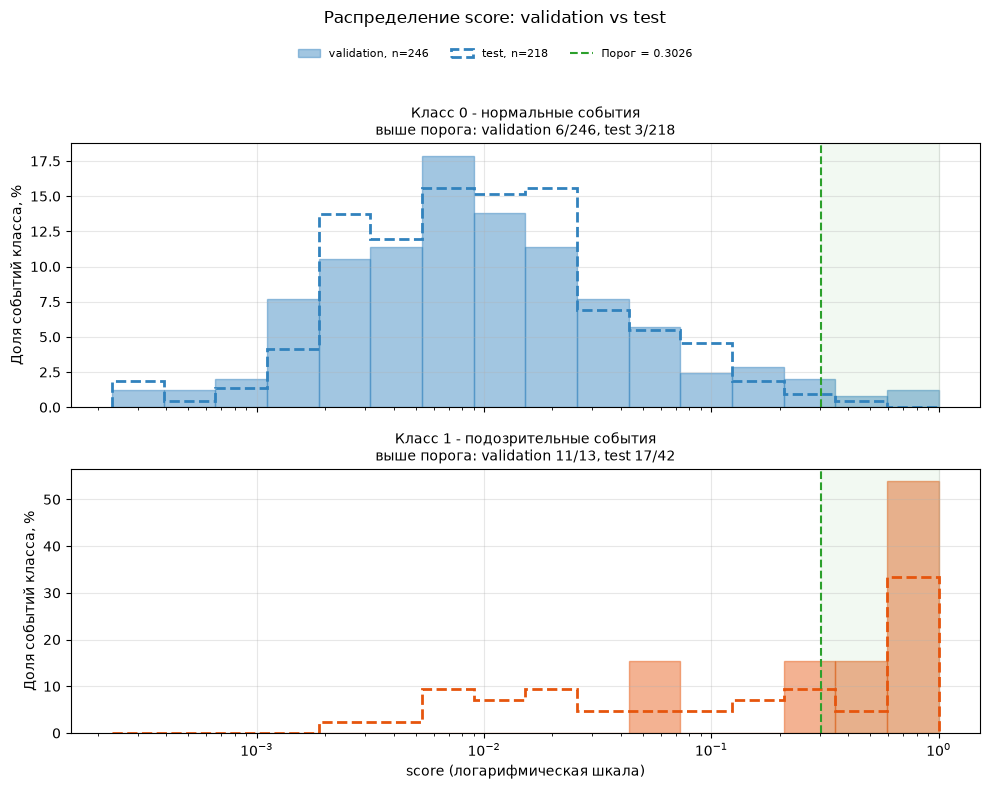

Сохранено в artifacts/score_shift_val_vs_test.png


In [18]:
# Overlay распределений score: validation vs test
val_scores_shift = best_pipeline.predict_proba(X_val)[:, 1]
test_scores_shift = test_scores
y_val_shift = np.asarray(y_val).astype(int)
y_test_shift = np.asarray(y_test).astype(int)

score_floor = max(1e-4, float(min(val_scores_shift.min(), test_scores_shift.min())))
bins = np.logspace(np.log10(score_floor), 0, 17)

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
panels = [
    (axes[0], 0, 'Класс 0 - нормальные события', '#3182bd'),
    (axes[1], 1, 'Класс 1 - подозрительные события', '#e6550d'),
]

for ax, cls, title, color in panels:
    val_cls = val_scores_shift[y_val_shift == cls]
    test_cls = test_scores_shift[y_test_shift == cls]

    val_weights = np.full(len(val_cls), 100.0 / len(val_cls))
    test_weights = np.full(len(test_cls), 100.0 / len(test_cls))

    ax.hist(val_cls, bins=bins, weights=val_weights, alpha=0.45, color=color,
            edgecolor=color, label=f'validation, n={len(val_cls)}')
    ax.hist(test_cls, bins=bins, weights=test_weights, histtype='step',
            color=color, linestyle='--', linewidth=2.0,
            label=f'test, n={len(test_cls)}')

    ax.axvspan(best_threshold, 1.0, color='#2ca02c', alpha=0.06)
    ax.axvline(best_threshold, color='#2ca02c', linestyle='--', linewidth=1.5,
               label=f'Порог = {best_threshold:.4f}')

    val_above = int((val_cls >= best_threshold).sum())
    test_above = int((test_cls >= best_threshold).sum())
    ax.set_title(
        f'{title}\nвыше порога: validation {val_above}/{len(val_cls)}, '
        f'test {test_above}/{len(test_cls)}',
        fontsize=10,
    )

    ax.set_xscale('log')
    ax.set_ylabel('Доля событий класса, %')
    ax.grid(alpha=0.3)

axes[-1].set_xlabel('score (логарифмическая шкала)')
fig.suptitle('Распределение score: validation vs test', fontsize=12)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4,
           bbox_to_anchor=(0.5, 0.945), frameon=False, fontsize=8)
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.savefig(ARTIFACTS_PATH / 'score_shift_val_vs_test.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Сохранено в {ARTIFACTS_PATH / "score_shift_val_vs_test.png"}')

In [19]:
df_test = df[df['source_row_id'].isin(test_ids)].copy()
df_test['y_true'] = y_test.values
df_test['y_pred'] = y_pred_test
df_test['score'] = test_scores

threshold_for_display = best_threshold

display_cols = ['event_id', 'y_true', 'y_pred', 'score', 'known_device', 'new_country', 'vpn_used']

# FP примеры
fp_examples = df_test[(df_test['y_true'] == 0) & (df_test['y_pred'] == 1)].copy()
fp_examples['threshold'] = threshold_for_display
print(f'=== FP (ложные срабатывания): {len(fp_examples)} (порог = {threshold_for_display:.4f}) ===')
if len(fp_examples) > 0:
    fp_show = fp_examples[display_cols + ['threshold']].head(3).copy()
    fp_show['score'] = fp_show['score'].round(4)
    display(fp_show)
else:
    print('FP отсутствуют')

# FN примеры
fn_examples = df_test[(df_test['y_true'] == 1) & (df_test['y_pred'] == 0)].copy()
fn_examples['threshold'] = threshold_for_display
print(f'\n=== FN (пропущенные угрозы): {len(fn_examples)} (порог = {threshold_for_display:.4f}) ===')
if len(fn_examples) > 0:
    fn_show = fn_examples[display_cols + ['threshold']].head(3).copy()
    fn_show['score'] = fn_show['score'].round(4)
    display(fn_show)
else:
    print('FN отсутствуют')

=== FP (ложные срабатывания): 3 (порог = 0.3026) ===


,event_id,y_true,y_pred,score,known_device,new_country,vpn_used,threshold
77,evt_000988,0,1,0.3033,1,0,0,0.302633
93,evt_001140,0,1,0.3178,1,1,0,0.302633
988,evt_001318,0,1,0.3727,0,0,0,0.302633



=== FN (пропущенные угрозы): 25 (порог = 0.3026) ===


,event_id,y_true,y_pred,score,known_device,new_country,vpn_used,threshold
18,evt_000966,1,0,0.0032,1,0,0,0.302633
32,evt_000497,1,0,0.2030,0,0,0,0.302633
99,evt_000238,1,0,0.0108,1,0,0,0.302633


### Анализ ошибок на test

На test при пороге 0.3036 получено 2 FP и 25 FN. Модель намеренно выбрана по правилу с приоритетом recall на validation, но на test доля класса 1 выросла с 5.02 % до 16.15 %, и распределение score сдвинулось. В результате recall упал до 0.4048, а precision выросла до 0.8947.

Первый FP это стандартное событие на известном устройстве в привычной стране, где модель допустила перестраховку, второй объясняется редким контекстом (новая страна на известном устройстве), а третий - происходит на неизвестном устройстве. Сигналы вроде новой страны или незнакомого устройства входят в число "тревожных", поэтому модель склонна на них реагировать.

Два из трех FN выглядят "обычно" по поведенческим признакам: неизменный контекст устройства и страны, без VPN. Один FN (evt_000497) происходит на неизвестном устройстве, однако одного этого признака модели не хватило, чтобы распознать угрозу, так как остальной контекст выглядел нормально. Модель не находит в этих событиях совокупности тревожных сигналов. Это ожидаемое ограничение: если событие похоже на нормальное по всем доступным признакам, кроме скрытой метки, классификатор не может его выделить.

In [20]:
# --- Дополнительный разбор варианта 3: known_device, validation vs test ---

# 1. Собираем df_val_analysis по той же схеме, что df_test в bf1e0c4d
df_val_analysis = df[df['source_row_id'].isin(val_ids)].copy()
val_scores_final = best['pipeline'].predict_proba(X_val)[:, 1]
y_pred_val_final = (val_scores_final >= best['threshold']).astype(int)

df_val_analysis['y_true'] = y_val.values
df_val_analysis['y_pred'] = y_pred_val_final
df_val_analysis['score'] = val_scores_final


def subgroup_table(df_part, feat, label):
    rows = []
    for group_val, g in df_part.groupby(feat, observed=True):
        y_t = g['y_true'].values
        y_p = g['y_pred'].values
        tp = int(((y_t == 1) & (y_p == 1)).sum())
        fp = int(((y_t == 0) & (y_p == 1)).sum())
        fn = int(((y_t == 1) & (y_p == 0)).sum())
        n = len(g)
        n_pos = int(y_t.sum())
        if n_pos > 0:
            recall_str = f'{tp}/{tp + fn} = {tp / (tp + fn):.3f}'
        else:
            recall_str = 'не определен (0 положительных)'
        rows.append({
            'часть': label,
            'подгруппа': group_val,
            'всего': n,
            'класс_1': n_pos,
            'TP': tp,
            'FP': fp,
            'FN': fn,
            'recall': recall_str,
        })
    return pd.DataFrame(rows)


known_val  = subgroup_table(df_val_analysis, 'known_device', 'validation')
known_test = subgroup_table(df_test,         'known_device', 'test')

combined = (
    pd.concat([known_val, known_test], ignore_index=True)
      .sort_values(['подгруппа', 'часть'])
      .reset_index(drop=True)
)

print('=== known_device: validation vs test ===')
display(combined)

=== known_device: validation vs test ===


,часть,подгруппа,всего,класс_1,TP,FP,FN,recall
0,test,0,26,16,9,1,7,9/16 = 0.562
1,validation,0,23,6,4,4,2,4/6 = 0.667
2,test,1,234,26,8,2,18,8/26 = 0.308
3,validation,1,236,7,7,2,0,7/7 = 1.000


### Дополнительный разбор варианта 3: known_device, validation vs test

- **validation:** для неизвестных устройств recall 4/6 = 0.667, для известных 7/7 = 1.000. Ловятся лучше известные.
- **test:** для неизвестных устройств recall 9/16 = 0.562, для известных 8/26 = 0.308. Ловятся лучше неизвестные.
- **Направление ошибки меняется** между частями. Это не перенос сигнала `known_device`, а смена поведения модели после сдвига распределения.
- **Основной вклад в падение recall на test** дает подгруппа `known_device=1`: 18 из 25 FN. Доля класса 1 внутри нее выросла с 7/236 = 3.0 % до 26/234 = 11.1 %, а фиксированный порог 0.3036 за этим сдвигом не успевает.
- В подгруппе `known_device=0` изменение умеренное: recall с 4/6 = 0.667 до 9/16 = 0.562, FP с 4 до 1. Здесь поведение относительно стабильно.
- Положительных на validation мало (6 и 7), поэтому recall 7/7 = 1.000 не является устойчивой оценкой.

Доли приведены с явным знаменателем в формате TP / (TP + FN). Подгрупп с нулем положительных нет, поэтому recall определен для всех четырех строк.

## Итоговый вывод

### Почему не RF min_samples_leaf=1

Формально на validation RF `min_samples_leaf=1` дает лучший recall (0.9231 против 0.8462 у LR), но эта конфигурация исключена из финального выбора как переобученная, потому что AP на test значительно ниже, чем на validation. Такое падение качества score при переходе на новые данные означает, что модель не уловила общие закономерности, а запомнила тренировочные события, из-за чего на тесте ее вероятности становятся хуже упорядоченными.

### Падение recall на test

Recall на test (0.4048) ниже, чем на validation (0.8462), почти на 44 п.п. Причины:

1. **Дрейф доли класса 1:** в test 16.15 % против 5.02 % в validation. Модель обучалась на другом распределении score, и порог, подобранный по validation, оказался слишком высоким.
2. **Временное разделение:** test содержит события из будущего относительно train. Состав атак и нормального поведения мог измениться.
3. **Фиксированный порог:** порог 0.3036 выбран по validation и не подстраивался под test.

Precision при этом выросла до 0.8947: поднятые 19 алертов почти все попали в реальные угрозы. Это не ошибка модели, а наблюдаемое свойство временного разделения - низкая нагрузка ценой большого числа FN. В эксплуатации требуется мониторинг.

### Выбор модели и порога

По правилу максимизации recall в рамках установленного лимита (31 алерт на validation) для финального решения выбрана LogisticRegression с параметрами `C=1` и `max_iter=2000`. Выбранный порог составляет 0.3036. Это минимальное значение score, при котором модель показывает максимальный recall (0.8462), не превышая допустимую нагрузку (17 алертов).

### Отличие от baseline

В качестве baseline использован `DummyClassifier(strategy="most_frequent")`, который всегда предсказывает класс 0. Он показывает высокую accuracy (0.9498), но нулевой recall и крайне низкий AP (0.0502). Это доказывает, что accuracy в условиях дисбаланса (91.5% нормальных событий) не отражает качество детектора. Выбранная модель LogisticRegression превосходит baseline по ключевым для ИБ метрикам: recall (0.8462) и AP (0.7356), то есть она способна реально находить угрозы, а не просто угадывать мажоритарный класс.

### Компромисс FP/FN и стоимость

На выбранном пороге модель допускает 6 ложных тревог (FP) и пропускает 2 угрозы (FN). Согласно учебной формуле `cost = fp + 20*fn`, стоимость такой конфигурации составляет `6 + 20*2 = 46`. Для сравнения: исходный порог 0.5 дает 5 FP и 6 FN (стоимость 125), а более агрессивный порог 0.2125 — 10 FP и 2 FN (стоимость 50). Выбранный порог 0.3036 обеспечивает наилучший компромисс: он минимизирует учебную стоимость среди допустимых точек и одновременно максимизирует recall, не выходя за рамки лимита алертов.

### Ограничения

1. **Синтетическая природа данных.** Набор сгенерирован искусственно, поэтому распределения признаков и правило разметки могут не соответствовать реальному SOC. Метрики, полученные на таком наборе, нельзя напрямую переносить в эксплуатацию без проверки на реальных данных, так как возможны неизвестные скрытые зависимости между полями.
2. **Сценарий разделения (временное разделение).** Тестовая выборка содержит события из будущего относительно train, но пользователи (`user_id`) пересекаются между train, validation и test. Это проверяет способность модели предсказывать будущие события для уже известных пользователей, но не гарантирует независимость по учетным записям и не оценивает качество на совершенно новых пользователях.
3. **Перенос фиксированного порога на рабочий поток.** Порог 0.3036 зафиксирован по validation и применен к test без изменений. Из-за временного дрейфа распределения score он дал падение recall на 44 п.п. В реальном рабочем потоке это требует постоянного мониторинга доли алертов и периодического пересмотра порога на новых данных, так как жестко зафиксированный порог со временем теряет эффективность.

### Стоимость ошибок

- **FP:** ложная тревога, расход времени аналитика SOC на проверку нормального события; на test 2 FP.
- **FN:** пропущенная угроза, риск компрометации; на test 25 FN, что дает `cost = 2 + 20*25 = 502`.